# Practical Application III: Comparing Classifiers

**Client:** a Portuguese retail bank that sells long-term deposits by telephone.

**Question:** which clients are most likely to say yes to a term deposit, so the call centre can phone them first?

**Approach:** compare four classifiers (k-nearest neighbors, logistic regression, decision tree and support vector machine) on the bank's records of past telemarketing calls, following the CRISP-DM process: business understanding, data understanding, data preparation, modeling, evaluation and recommendations.

## Problem 1: Understanding the Data

The accompanying paper (Moro, Laureano and Cortez, *Using Data Mining for Bank Direct Marketing*, CRISP-DM-BANK.pdf, section 2 "Materials and Methods") describes the data as the result of **17 telemarketing campaigns** run by the bank between **May 2008 and November 2010**, covering 79,354 contacts in total. Each campaign offered a long-term deposit with an attractive interest rate; a call counts as a success if the client subscribed.

The file used here, `bank-additional-full.csv`, is the UCI version of that data: 41,188 calls, ordered by date, with 20 inputs plus the outcome `y`. It adds five social and economic indicators (employment rate, consumer price and confidence indices, the 3-month Euribor rate and the number of bank employees) to the client and call details.

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance

# Silence library warnings (including in the parallel grid-search workers) to keep the output readable
os.environ['PYTHONWARNINGS'] = 'ignore'
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12})
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#b8b6ad'
RANDOM_STATE = 42

## Problem 2: Read in the Data

The file is semicolon-separated.

In [2]:
bank = pd.read_csv('data/bank-additional-full.csv', sep=';')
print(f'{bank.shape[0]:,} calls, {bank.shape[1]} columns')
bank.head()

41,188 calls, 21 columns


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## Problem 3: Understanding the Features

Three checks: data types, missing values and anything that would mislead a model.

In [3]:
bank.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [4]:
# No column has NaN values, but six categorical columns use the label 'unknown' for missing answers
unknown_counts = (bank.select_dtypes('object') == 'unknown').sum()
unknown_counts = unknown_counts[unknown_counts > 0].sort_values(ascending=False)
pd.DataFrame({'unknown rows': unknown_counts,
              'share of rows': (unknown_counts / len(bank)).map('{:.1%}'.format)})

,unknown rows,share of rows
default,8597,20.9%
education,1731,4.2%
housing,990,2.4%
loan,990,2.4%
job,330,0.8%
marital,80,0.2%


In [5]:
print('Exact duplicate rows:', bank.duplicated().sum())
print('Clients never contacted before (pdays = 999):', f"{(bank['pdays'] == 999).mean():.1%}")
print('Clients known to be in default:', (bank['default'] == 'yes').sum())

Exact duplicate rows: 12
Clients never contacted before (pdays = 999): 96.3%
Clients known to be in default: 3


**What this tells us**

- **Data types are correct.** The 10 numeric columns are already numbers and the 11 text columns are categories, so nothing needs to be coerced.
- **Missing values are hidden as `'unknown'`.** There are no blanks, but `default` is unknown for 21% of clients, `education` for 4% and `housing`/`loan` for 2%. These are kept as their own category: for `default`, "unknown" turns out to be informative (clients unwilling to say tend to subscribe less), and dropping 21% of the rows would waste data.
- **12 rows are exact duplicates** and are removed before modeling.
- **`pdays` uses 999 as a code for "never contacted".** 96% of clients have this value, so it is replaced with a yes/no flag `contacted_before`; treating 999 as a real number of days would distort any distance-based model.
- **`default = yes` occurs only 3 times**, too rare to learn from, but harmless as a category.
- **`duration` must be left out.** Call length is only known after the call has ended, by which time the outcome is known too. The data description warns that it should only be used as a benchmark, so it is excluded from every model.

In [6]:
bank = bank.drop_duplicates().reset_index(drop=True)
bank['subscribed'] = (bank['y'] == 'yes').astype(int)
print(f'{len(bank):,} calls after removing duplicates')
print(f"Overall subscription rate: {bank['subscribed'].mean():.1%}")

41,176 calls after removing duplicates
Overall subscription rate: 11.3%


### Exploring the data

The outcome is unbalanced: only about 1 call in 9 ends in a subscription. That shapes everything that follows, including how models are scored.

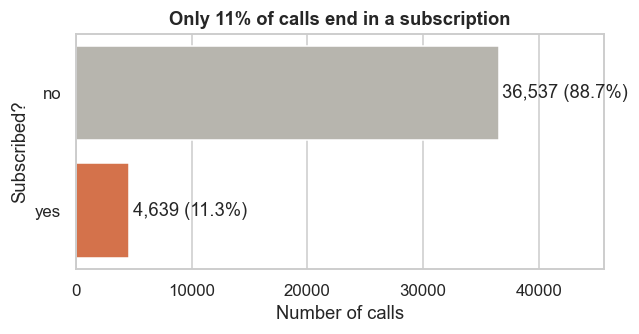

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.2))
outcome_counts = bank['y'].value_counts()
sns.barplot(x=outcome_counts.values, y=outcome_counts.index, hue=outcome_counts.index,
            palette=[GREY, ORANGE], legend=False, ax=ax)
for i, v in enumerate(outcome_counts.values):
    ax.text(v + 300, i, f'{v:,} ({v / len(bank):.1%})', va='center')
ax.set(title='Only 11% of calls end in a subscription', xlabel='Number of calls', ylabel='Subscribed?')
ax.set_xlim(0, outcome_counts.max() * 1.25)
plt.tight_layout()
plt.savefig('images/outcome_balance.png', bbox_inches='tight')
plt.show()

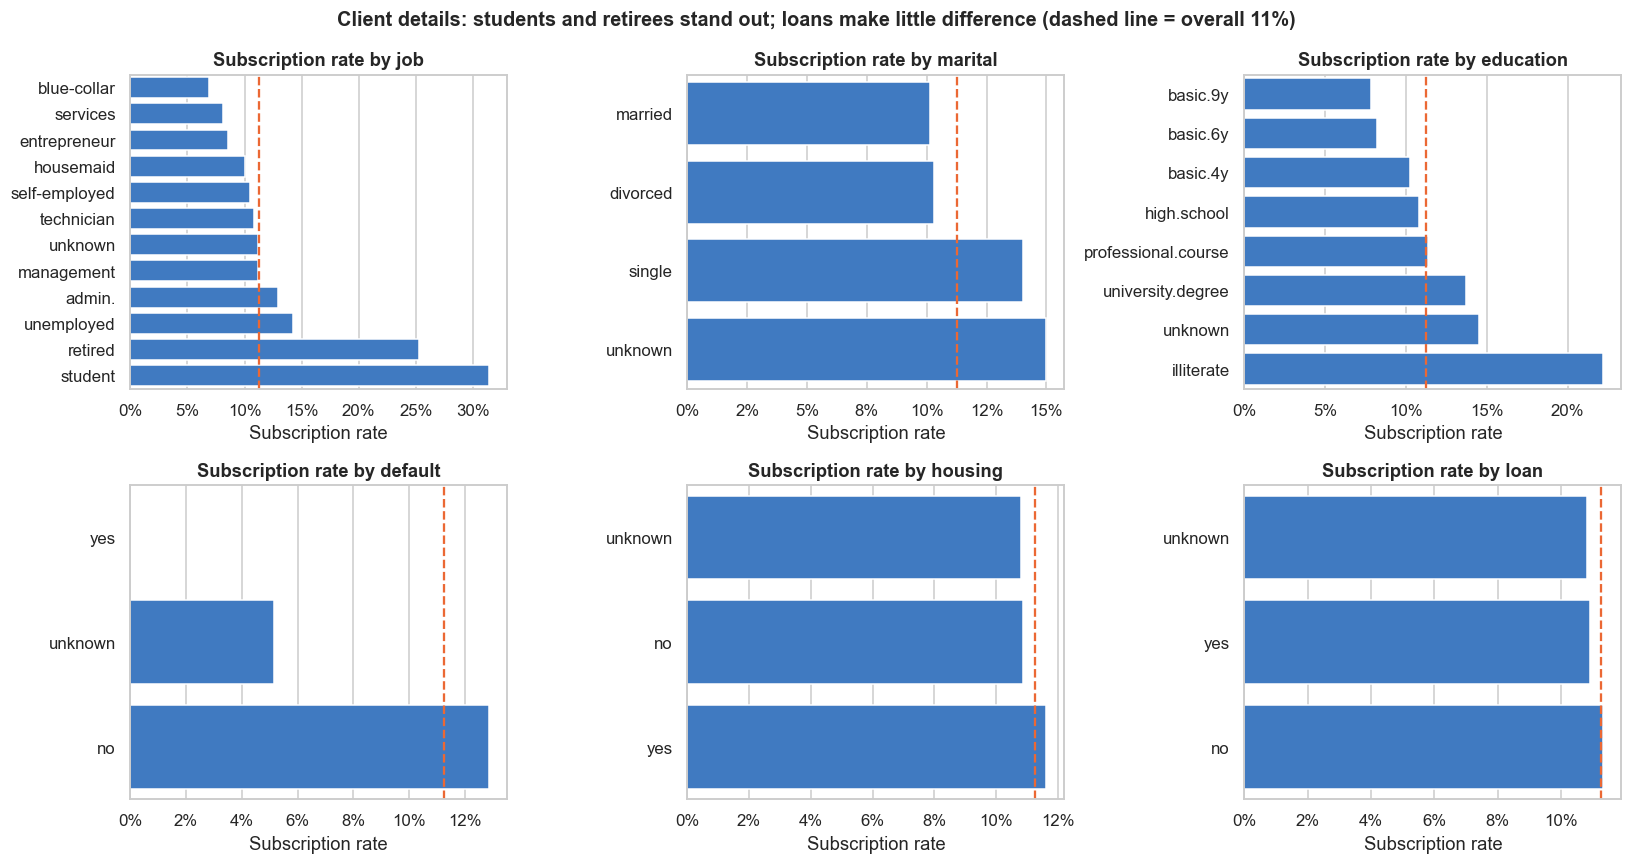

In [8]:
def plot_rates(ax, column, order=None, title=None):
    """Bar chart of the subscription rate for each category of a column, with the overall rate as a line."""
    rates = bank.groupby(column)['subscribed'].mean()
    rates = rates.reindex(order) if order is not None else rates.sort_values()
    sns.barplot(x=rates.values, y=rates.index.astype(str), color=BLUE, ax=ax)
    ax.axvline(bank['subscribed'].mean(), color=ORANGE, ls='--', lw=1.5)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set(title=title or column, xlabel='Subscription rate', ylabel='')


client_columns = ['job', 'marital', 'education', 'default', 'housing', 'loan']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.flat, client_columns):
    plot_rates(ax, column, title=f'Subscription rate by {column}')
fig.suptitle('Client details: students and retirees stand out; loans make little difference '
             '(dashed line = overall 11%)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('images/client_features.png', bbox_inches='tight')
plt.show()

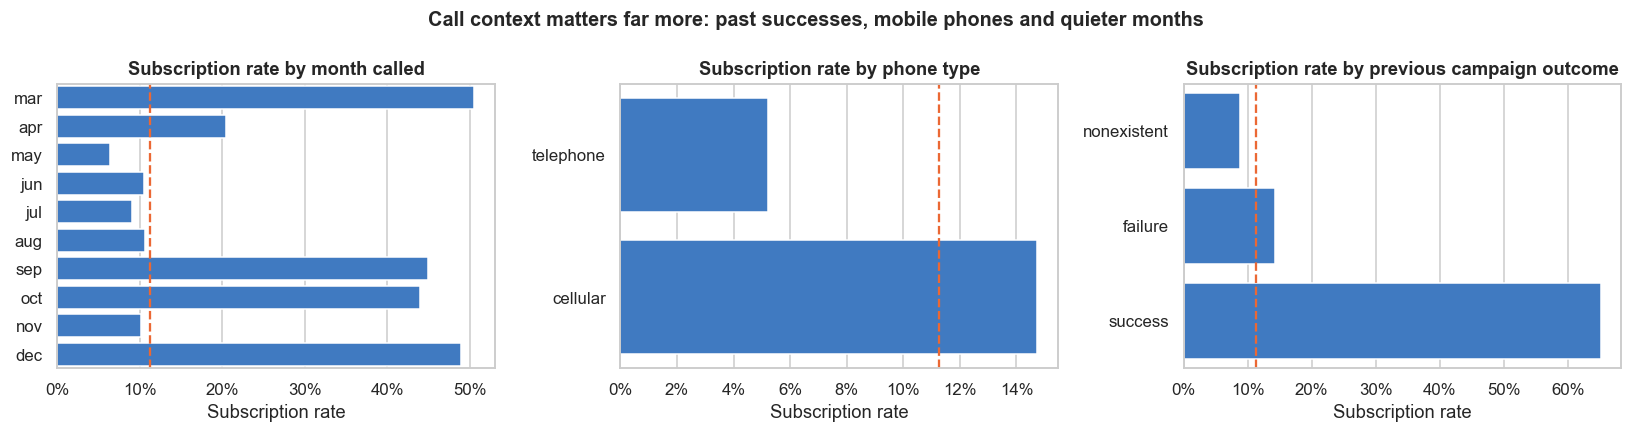

Calls per month: {'mar': 546, 'apr': 2631, 'may': 13767, 'jun': 5318, 'jul': 7169, 'aug': 6176, 'sep': 570, 'oct': 717, 'nov': 4100, 'dec': 182}


In [9]:
month_order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_rates(axes[0], 'month', order=month_order, title='Subscription rate by month called')
plot_rates(axes[1], 'contact', title='Subscription rate by phone type')
plot_rates(axes[2], 'poutcome', order=['nonexistent', 'failure', 'success'],
           title='Subscription rate by previous campaign outcome')
fig.suptitle('Call context matters far more: past successes, mobile phones and quieter months',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('images/call_context.png', bbox_inches='tight')
plt.show()

calls_per_month = bank['month'].value_counts().reindex(month_order)
print('Calls per month:', calls_per_month.to_dict())

May has by far the most calls and the lowest success rate, while March, September, October and December have few calls but succeed 44-51% of the time. Some of this is timing within the 2008-2010 period (the busy months were early in the data, before rates and the economy changed), so month partly stands in for the economic conditions below.

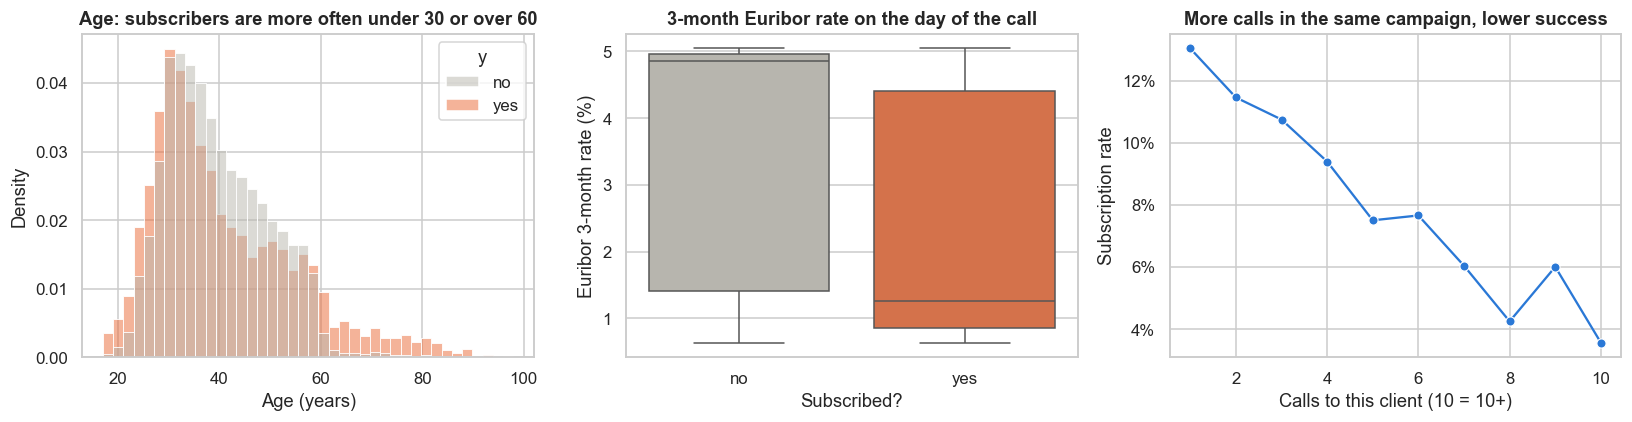

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(data=bank, x='age', hue='y', stat='density', common_norm=False, bins=40,
             palette=[GREY, ORANGE], ax=axes[0])
axes[0].set(title='Age: subscribers are more often under 30 or over 60', xlabel='Age (years)')

sns.boxplot(data=bank, x='y', y='euribor3m', hue='y', palette=[GREY, ORANGE], legend=False, ax=axes[1])
axes[1].set(title='3-month Euribor rate on the day of the call', xlabel='Subscribed?',
            ylabel='Euribor 3-month rate (%)')

campaign_rate = bank.assign(calls=bank['campaign'].clip(upper=10)).groupby('calls')['subscribed'].mean()
sns.lineplot(x=campaign_rate.index, y=campaign_rate.values, marker='o', color=BLUE, ax=axes[2])
axes[2].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[2].set(title='More calls in the same campaign, lower success', xlabel='Calls to this client (10 = 10+)',
            ylabel='Subscription rate')
plt.tight_layout()
plt.savefig('images/numeric_features.png', bbox_inches='tight')
plt.show()

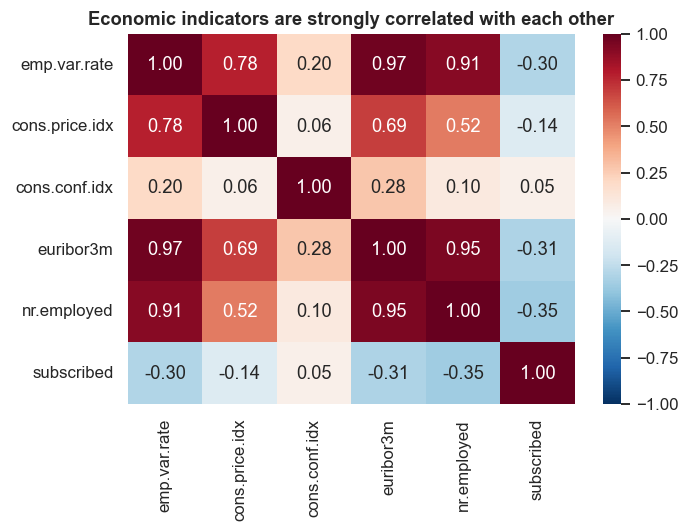

In [11]:
# The five economic indicators move together, which matters when reading model coefficients
economic = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(bank[economic + ['subscribed']].corr(), annot=True, fmt='.2f', cmap='RdBu_r',
            vmin=-1, vmax=1, ax=ax)
ax.set_title('Economic indicators are strongly correlated with each other')
plt.tight_layout()
plt.show()

### Inferential statistics: are these differences real?

A chi-square test checks, for each categorical feature, whether the subscription rate differs between its categories by more than chance would explain. A Mann-Whitney test does the same for numeric features, comparing subscribers with non-subscribers. Cramer's V (0 = no link, 1 = perfect link) shows how *strong* each link is, which matters because with 41,000 rows even tiny differences are "significant".

In [12]:
rows = []
for column in bank.select_dtypes('object').columns.drop('y'):
    table = pd.crosstab(bank[column], bank['y'])
    chi2, p_value, dof, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rows.append({'feature': column, 'test': 'chi-square', 'p-value': p_value, 'effect size': cramers_v})

for column in ['age', 'campaign', 'previous', 'euribor3m', 'nr.employed', 'emp.var.rate']:
    yes, no = bank.loc[bank['subscribed'] == 1, column], bank.loc[bank['subscribed'] == 0, column]
    u_stat, p_value = stats.mannwhitneyu(yes, no)
    rows.append({'feature': column, 'test': 'Mann-Whitney',
                 'p-value': p_value, 'effect size': abs(1 - 2 * u_stat / (len(yes) * len(no)))})

tests = pd.DataFrame(rows).sort_values('effect size', ascending=False).reset_index(drop=True)
tests['p-value'] = tests['p-value'].map(lambda p: '< 0.001' if p < 0.001 else f'{p:.3f}')
tests.round(3)

,feature,test,p-value,effect size
0,nr.employed,Mann-Whitney,< 0.001,0.498
1,euribor3m,Mann-Whitney,< 0.001,0.487
2,emp.var.rate,Mann-Whitney,< 0.001,0.433
3,poutcome,chi-square,< 0.001,0.321
4,month,chi-square,< 0.001,0.275
5,previous,Mann-Whitney,< 0.001,0.219
6,job,chi-square,< 0.001,0.153
7,contact,chi-square,< 0.001,0.145
8,campaign,Mann-Whitney,< 0.001,0.110
9,default,chi-square,< 0.001,0.099


**Reading the tests.** Almost every feature is statistically linked to subscribing, but the strength varies a lot. The economic indicators (employment, Euribor) and the outcome of the previous campaign have the strongest links, followed by month and contact type. Personal details such as job and education are weaker, and **having a housing or personal loan makes no real difference** (p-values above 0.05). The effect size for numeric features is the rank-biserial correlation, read on the same 0-1 scale.

## Problem 4: Understanding the Task

**Business objective:** the bank wants to sell more term deposits for less call-centre effort. Each campaign calls thousands of clients and only about 11% subscribe, so most calls are wasted, cost agent time and can annoy clients.

**As a data problem:** a **binary classification** task. Using only information available *before* a call (client details, past contact history, the calendar and the economic situation), predict the probability that a client will subscribe, so the bank can **rank clients and call the most promising ones first**. Success means a model that finds more subscribers per call than calling at random, and that explains *which* clients and conditions make a "yes" more likely.

## Problem 5: Engineering Features

The first models use **only the seven bank client features** (age, job, marital status, education, default, housing loan, personal loan), as the assignment asks. Categorical columns are one-hot encoded and age is standardized, inside a pipeline so that the same steps are applied to training and test data.

In [13]:
client_features = ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan']
X_client = bank[client_features]
y = bank['subscribed']

client_preprocessor = make_column_transformer(
    (OneHotEncoder(handle_unknown='ignore'), ['job', 'marital', 'education', 'default', 'housing', 'loan']),
    (StandardScaler(), ['age']),
)
print('Feature matrix shape after encoding:', client_preprocessor.fit_transform(X_client).shape)

Feature matrix shape after encoding: (41176, 34)


## Problem 6: Train/Test Split

25% of the calls are held back as a test set. The split is **stratified** so that both sets keep the 11% subscription rate.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X_client, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print(f'Train: {len(X_train):,} calls ({y_train.mean():.1%} subscribed)')
print(f'Test:  {len(X_test):,} calls ({y_test.mean():.1%} subscribed)')

Train: 30,882 calls (11.3% subscribed)
Test:  10,294 calls (11.3% subscribed)


## Problem 7: A Baseline Model

The simplest possible "model" predicts the most common answer, **no**, for every client. Because 89% of clients say no, this scores about 89% accuracy while finding **zero** subscribers. Any useful model has to beat it on more than accuracy.

In [15]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
baseline_accuracy = baseline.score(X_test, y_test)
print(f'Baseline accuracy (always predict "no"): {baseline_accuracy:.3f}')
print('Subscribers found by the baseline:', baseline.predict(X_test).sum())

Baseline accuracy (always predict "no"): 0.887
Subscribers found by the baseline: 0


## Problem 8: A Simple Model

A logistic regression on the seven client features.

In [16]:
logistic_simple = Pipeline([
    ('preprocess', client_preprocessor),
    ('model', LogisticRegression(max_iter=1000)),
]).fit(X_train, y_train)

## Problem 9: Score the Model

In [17]:
simple_accuracy = logistic_simple.score(X_test, y_test)
simple_auc = roc_auc_score(y_test, logistic_simple.predict_proba(X_test)[:, 1])
print(f'Test accuracy: {simple_accuracy:.3f}  (baseline {baseline_accuracy:.3f})')
print(f'Test ROC AUC:  {simple_auc:.3f}  (baseline 0.500)')
print('Subscribers predicted:', logistic_simple.predict(X_test).sum())

Test accuracy: 0.887  (baseline 0.887)
Test ROC AUC:  0.654  (baseline 0.500)
Subscribers predicted: 0


The accuracy is **identical to the baseline**: with client details alone, no client looks likely enough to cross the 50% line, so the model still says "no" to everyone. Its ROC AUC of about 0.65 shows it *can* rank clients somewhat better than chance, but accuracy hides that completely. This is the first sign that accuracy is the wrong yardstick for this problem.

## Problem 10: Model Comparisons

All four classifiers with their default settings, on the same client features. Fit time, train accuracy and test accuracy as requested, plus test ROC AUC for reasons explained in Problem 11.

In [18]:
default_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'SVM': SVC(random_state=RANDOM_STATE),
}


def ranking_scores(fitted, X):
    """Probability (or SVM decision score) of a 'yes', used to rank clients."""
    if hasattr(fitted, 'predict_proba'):
        return fitted.predict_proba(X)[:, 1]
    return fitted.decision_function(X)


rows = []
for name, model in default_models.items():
    pipe = Pipeline([('preprocess', client_preprocessor), ('model', model)])
    start = time.perf_counter()
    pipe.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    rows.append({'Model': name,
                 'Train Time (s)': fit_seconds,
                 'Train Accuracy': pipe.score(X_train, y_train),
                 'Test Accuracy': pipe.score(X_test, y_test),
                 'Test ROC AUC': roc_auc_score(y_test, ranking_scores(pipe, X_test))})

default_results = pd.DataFrame(rows).set_index('Model')
default_results.round(3)

,Train Time (s),Train Accuracy,Test Accuracy,Test ROC AUC
Model,,,,
Logistic Regression,0.067,0.887,0.887,0.654
KNN,0.038,0.892,0.879,0.594
Decision Tree,0.315,0.918,0.863,0.582
SVM,49.250,0.888,0.887,0.592


**What the table shows**

- **Every model's test accuracy sits at or just below the 88.7% baseline.** None of them is genuinely useful by this measure.
- **The decision tree memorises the training data** (highest train accuracy) but does worse on the test set: classic overfitting with no depth limit.
- **SVM takes by far the longest to fit** (tens of seconds against well under a second for the others) for no gain.
- **Logistic regression ranks clients best** (highest ROC AUC) and is the fastest, so it is a strong simple choice.

Two things should improve this: better features (the call context and economic data, which the exploration showed matter far more) and tuning each model against a metric that fits the business goal.

## Problem 11: Improving the Model

### Choosing the evaluation metric

**Accuracy is the wrong metric here.** With 89% "no" answers, a model can be 89% accurate and useless. The bank's real decision is **who to call first** with a limited number of agents, so what matters is how well a model *ranks* clients from most to least likely to subscribe.

The main metric is therefore **ROC AUC**: the chance that the model scores a randomly chosen subscriber above a randomly chosen non-subscriber (0.5 = guessing, 1.0 = perfect). It does not depend on any one cut-off, and it is not fooled by the imbalance. Alongside it, the results report **recall** (share of subscribers found) and **precision** (share of calls that succeed), and finally a business view: *if the bank calls the top X% of clients, what share of all subscribers does it reach?*

### Features for the improved models

All information available **before** a call is now used: client details, contact type, month and weekday, number of calls in this campaign, previous contacts and their outcome, the new `contacted_before` flag, and the five economic indicators. `duration` stays out (it is only known after the call), and so does the raw `pdays`.

In [19]:
categorical_features = ['job', 'marital', 'education', 'default', 'housing', 'loan',
                        'contact', 'month', 'day_of_week', 'poutcome']
numeric_features = ['age', 'campaign', 'previous', 'contacted_before',
                    'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

bank['contacted_before'] = (bank['pdays'] != 999).astype(int)
X_full = bank[categorical_features + numeric_features]

full_preprocessor = make_column_transformer(
    (OneHotEncoder(handle_unknown='ignore'), categorical_features),
    (StandardScaler(), numeric_features),
)

# Same rows in train and test as before, so results are directly comparable
X_train_full, X_test_full = X_full.loc[X_train.index], X_full.loc[X_test.index]
print('Encoded feature count:', full_preprocessor.fit_transform(X_train_full).shape[1])

Encoded feature count: 62


### Grid search with cross-validation

Each model is tuned with **5-fold stratified cross-validation** on the training set only, choosing the settings with the best ROC AUC. The grids are deliberately small and focused on each model's most important settings:

- **Logistic regression:** regularization strength `C`, and whether to re-weight the rare "yes" class.
- **KNN:** number of neighbors (the default of 5 is very noisy for an 11% class) and distance weighting.
- **Decision tree:** maximum depth and minimum leaf size, to stop the overfitting seen above.
- **SVM:** kernel and `C`. SVM training time grows quickly with data size, so its grid search uses a stratified sample of 8,000 training calls; the best SVM is then evaluated on the full test set like the others.

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search_space = {
    'Logistic Regression': (LogisticRegression(max_iter=2000),
                            {'model__C': [0.01, 0.1, 1, 10], 'model__class_weight': [None, 'balanced']}),
    'KNN': (KNeighborsClassifier(),
            {'model__n_neighbors': [5, 25, 75, 151], 'model__weights': ['uniform', 'distance']}),
    'Decision Tree': (DecisionTreeClassifier(random_state=RANDOM_STATE),
                      {'model__max_depth': [3, 5, 7, 10], 'model__min_samples_leaf': [20, 50, 100],
                       'model__class_weight': [None, 'balanced']}),
    'SVM': (SVC(random_state=RANDOM_STATE),
            {'model__kernel': ['linear', 'rbf'], 'model__C': [0.1, 1], 'model__class_weight': [None, 'balanced']}),
}

# Stratified sample of the training set for the slower SVM search
X_svm_sample, _, y_svm_sample, _ = train_test_split(
    X_train_full, y_train, train_size=8000, stratify=y_train, random_state=RANDOM_STATE)

grids, rows = {}, []
for name, (model, params) in search_space.items():
    X_fit, y_fit = (X_svm_sample, y_svm_sample) if name == 'SVM' else (X_train_full, y_train)
    pipe = Pipeline([('preprocess', full_preprocessor), ('model', model)])
    grid = GridSearchCV(pipe, params, scoring='roc_auc', cv=cv, n_jobs=-1)
    start = time.perf_counter()
    grid.fit(X_fit, y_fit)
    search_seconds = time.perf_counter() - start
    grids[name] = grid

    scores = ranking_scores(grid.best_estimator_, X_test_full)
    predictions = grid.predict(X_test_full)
    rows.append({'Model': name,
                 'Best settings': {k.replace('model__', ''): v for k, v in grid.best_params_.items()},
                 'Search time (s)': search_seconds,
                 'CV ROC AUC': grid.best_score_,
                 'Test ROC AUC': roc_auc_score(y_test, scores),
                 'Test Accuracy': accuracy_score(y_test, predictions),
                 'Test Recall': recall_score(y_test, predictions),
                 'Test Precision': precision_score(y_test, predictions, zero_division=0)})

tuned_results = pd.DataFrame(rows).set_index('Model').sort_values('Test ROC AUC', ascending=False)
pd.set_option('display.max_colwidth', 80)
tuned_results.round(3)

,Best settings,Search time (s),CV ROC AUC,Test ROC AUC,Test Accuracy,Test Recall,Test Precision
Model,,,,,,,
Logistic Regression,"{'C': 0.1, 'class_weight': 'balanced'}",7.410,0.789,0.802,0.832,0.641,0.361
KNN,"{'n_neighbors': 151, 'weights': 'uniform'}",14.863,0.782,0.801,0.900,0.205,0.686
Decision Tree,"{'class_weight': 'balanced', 'max_depth': 7, 'min_samples_leaf': 100}",8.167,0.783,0.798,0.820,0.651,0.342
SVM,"{'C': 1, 'class_weight': 'balanced', 'kernel': 'rbf'}",26.748,0.774,0.790,0.843,0.636,0.383


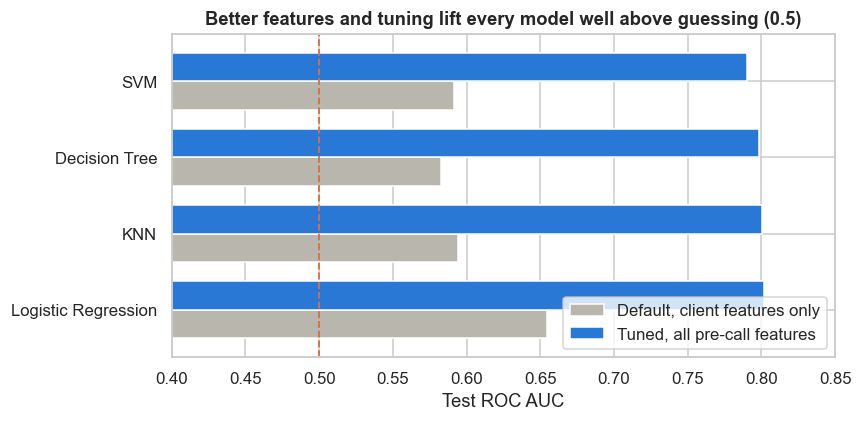

In [21]:
comparison = pd.DataFrame({'Default, client features only': default_results['Test ROC AUC'],
                           'Tuned, all pre-call features': tuned_results['Test ROC AUC']})
ax = comparison.plot.barh(figsize=(8, 4), color=[GREY, BLUE], width=0.75)
ax.axvline(0.5, color=ORANGE, ls='--', lw=1.2)
ax.set(title='Better features and tuning lift every model well above guessing (0.5)',
       xlabel='Test ROC AUC', ylabel='', xlim=(0.4, 0.85))
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('images/model_comparison.png', bbox_inches='tight')
plt.show()

**Reading the comparison**

- **Adding the call-context and economic features matters more than the choice of model.** Every model jumps from 0.58-0.65 ROC AUC to 0.79-0.80.
- **Once tuned, the four models rank clients almost equally well** (test ROC AUC 0.79 to 0.80). Logistic regression is marginally the best, and it is also fast and explainable. KNN needed 151 neighbors to get there and must keep all 30,000 training calls in memory to score a new client; the SVM is the weakest and the slowest to train.
- **The decision rule matters as much as the model.** The models tuned with `class_weight='balanced'` (logistic regression, tree, SVM) flag many more clients: they find about 64% of subscribers, and roughly 1 in 3 of their flagged calls succeeds. KNN has no such option, so at the default 50% cut-off it looks the most accurate (90%) but finds only 21% of subscribers. Which trade-off is right depends on how many calls the bank can afford, which is why the ranking view below is the most useful one.

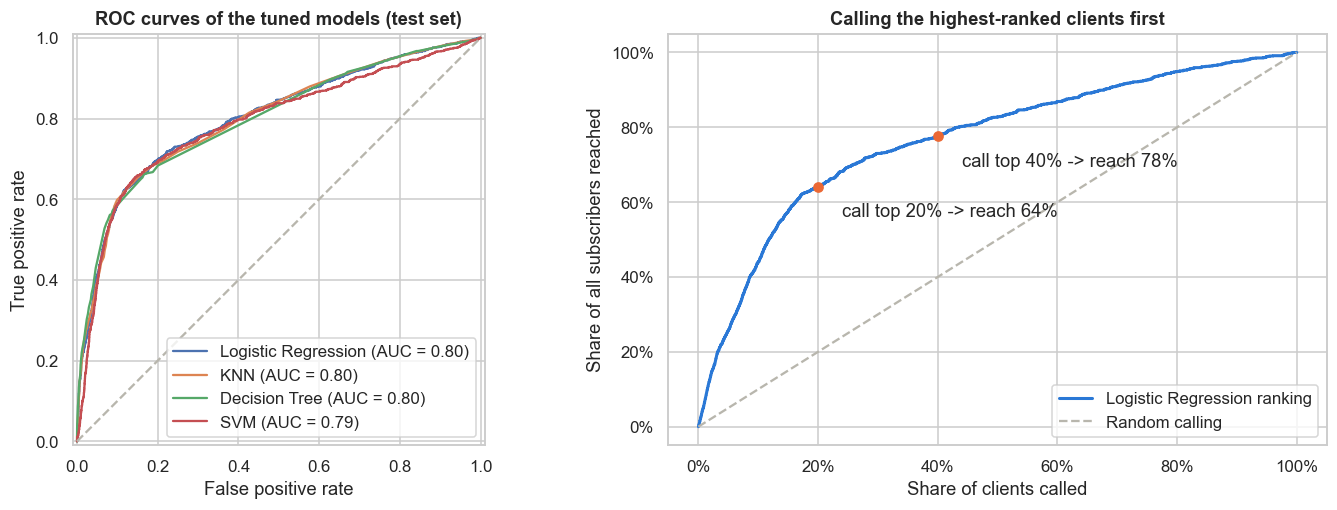

Calling the top 20% of clients reaches 64% of all subscribers; 36% of those calls succeed vs 11% at random (3.2x).


In [22]:
best_name = tuned_results.index[0]
best_model = grids[best_name].best_estimator_
best_scores = ranking_scores(best_model, X_test_full)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for name, grid in grids.items():
    RocCurveDisplay.from_predictions(y_test, ranking_scores(grid.best_estimator_, X_test_full),
                                     name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], ls='--', color=GREY)
axes[0].set(title='ROC curves of the tuned models (test set)',
            xlabel='False positive rate', ylabel='True positive rate')

# Gains chart: share of all subscribers reached when calling the top-ranked share of clients
order = np.argsort(-best_scores)
captured = np.cumsum(y_test.values[order]) / y_test.sum()
called = np.arange(1, len(order) + 1) / len(order)
axes[1].plot(called, captured, color=BLUE, lw=2, label=f'{best_name} ranking')
axes[1].plot([0, 1], [0, 1], ls='--', color=GREY, label='Random calling')
for share in [0.2, 0.4]:
    reached = captured[int(share * len(order)) - 1]
    axes[1].scatter(share, reached, color=ORANGE, zorder=3)
    axes[1].annotate(f'call top {share:.0%} -> reach {reached:.0%}', (share, reached),
                     xytext=(share + 0.04, reached - 0.08))
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set(title='Calling the highest-ranked clients first', xlabel='Share of clients called',
            ylabel='Share of all subscribers reached')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.savefig('images/gains_chart.png', bbox_inches='tight')
plt.show()

top20 = captured[int(0.2 * len(order)) - 1]
top20_rate = y_test.values[order][: int(0.2 * len(order))].mean()
print(f'Calling the top 20% of clients reaches {top20:.0%} of all subscribers; '
      f'{top20_rate:.0%} of those calls succeed vs {y_test.mean():.0%} at random ({top20_rate / y_test.mean():.1f}x).')

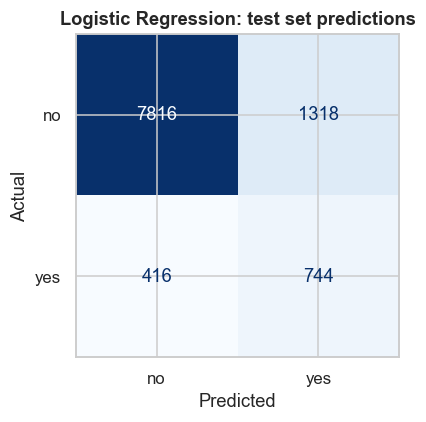

In [23]:
fig, ax = plt.subplots(figsize=(4.8, 4))
ConfusionMatrixDisplay.from_predictions(y_test, best_model.predict(X_test_full),
                                        display_labels=['no', 'yes'], cmap='Blues', colorbar=False, ax=ax)
ax.set(title=f'{best_name}: test set predictions', xlabel='Predicted', ylabel='Actual')
plt.tight_layout()
plt.show()

### Interpreting the logistic regression coefficients

Logistic regression is the easiest model to explain. Each coefficient is converted to an **odds ratio**: how much the odds of subscribing are multiplied, holding everything else fixed. An odds ratio of 2 means the odds double; 0.5 means they halve. For numeric features the change is for one standard deviation. Every category has its own column (there is no dropped reference level), so a category's ratio is best read against the other categories of the same feature, for example `contact_cellular` against `contact_telephone`.

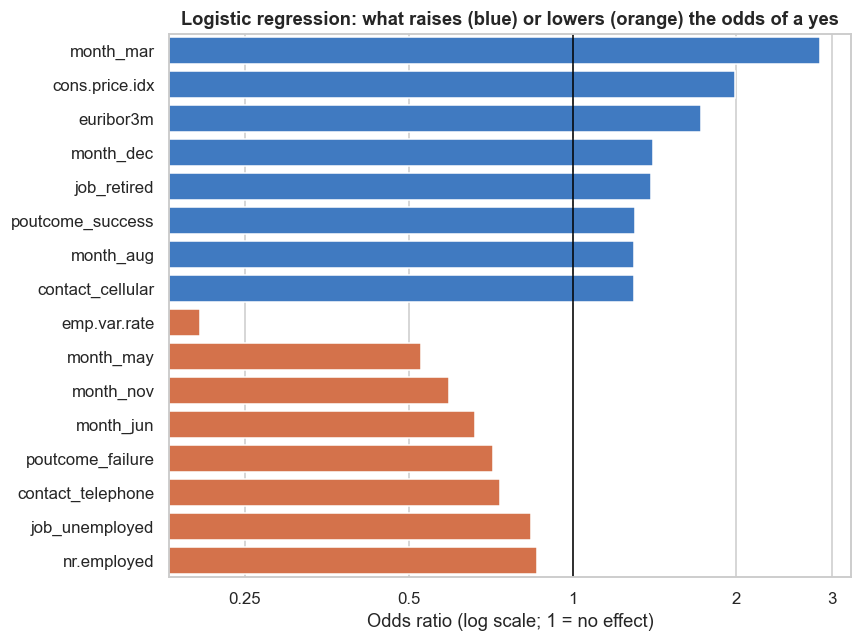

,odds ratio
emp.var.rate,0.21
month_mar,2.85
month_dec,1.40
month_may,0.53
poutcome_success,1.30
poutcome_failure,0.71
contact_cellular,1.30
contact_telephone,0.74
campaign,0.89
job_retired,1.39


In [24]:
logistic_best = grids['Logistic Regression'].best_estimator_
feature_names = logistic_best.named_steps['preprocess'].get_feature_names_out()
feature_names = [n.split('__', 1)[1] for n in feature_names]
odds = pd.Series(np.exp(logistic_best.named_steps['model'].coef_[0]), index=feature_names)

top = pd.concat([odds.sort_values(ascending=False).head(8), odds.sort_values().head(8)])
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=top.values, y=top.index, hue=top.values > 1, palette={True: BLUE, False: ORANGE},
            legend=False, ax=ax)
ax.axvline(1, color='black', lw=1)
ax.set_xscale('log')
ax.set_xticks([0.25, 0.5, 1, 2, 3])
ax.set_xticklabels(['0.25', '0.5', '1', '2', '3'])
ax.minorticks_off()
ax.set(title='Logistic regression: what raises (blue) or lowers (orange) the odds of a yes',
       xlabel='Odds ratio (log scale; 1 = no effect)', ylabel='')
plt.tight_layout()
plt.savefig('images/odds_ratios.png', bbox_inches='tight')
plt.show()
odds.loc[['emp.var.rate', 'month_mar', 'month_dec', 'month_may', 'poutcome_success', 'poutcome_failure',
          'contact_cellular', 'contact_telephone', 'campaign', 'job_retired', 'job_student',
          'housing_yes', 'loan_yes']].round(2).to_frame('odds ratio')

**What the coefficients say.** Directions are reliable; the exact sizes for the economic indicators are not, because those five indicators move together and the model can trade one off against another.

- **The economy has the largest effect.** A one-standard-deviation rise in the employment variation rate cuts the odds to about a fifth (odds ratio 0.21). Clients subscribed far more often in the downturn of 2009-2010, when employment was falling and interest rates were low, than in the boom months of 2008.
- **Month:** a call in March multiplies the odds by about 2.9 and December by 1.4, while May (0.53), November and June lower them.
- **Previous campaign outcome:** clients who said yes last time have about 1.8 times the odds of those who said no last time (1.30 vs 0.71). In the raw data, 65% of past subscribers said yes again against 9% of new contacts.
- **Mobile beats landline:** a call to a mobile phone has about 1.75 times the odds of a call to a landline (1.30 vs 0.74).
- **Repeated calling has diminishing returns:** each extra standard deviation of calls in the campaign (about 3 calls) lowers the odds by roughly 11%; the raw success rate falls from 13% on the first call to 6% by the fifth.
- **Retirees (1.39) and students (1.24)** are more likely to subscribe than other job groups, while **housing and personal loans have no effect** (odds ratios close to 1), matching the chi-square tests.

To check that these conclusions do not depend on one model's coefficients, permutation importance below measures how much the test ROC AUC drops when each feature is shuffled.

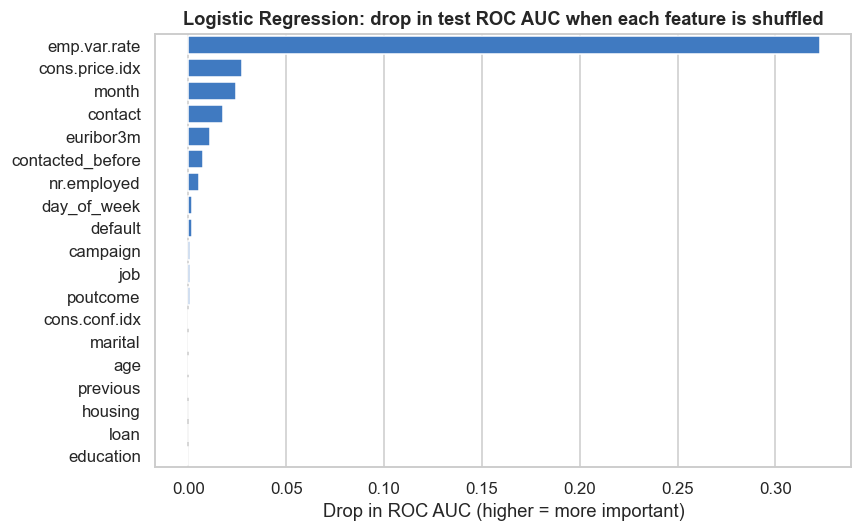

In [25]:
importance = permutation_importance(best_model, X_test_full, y_test, scoring='roc_auc',
                                    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(importance.importances_mean, index=X_test_full.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=importance.values, y=importance.index, color=BLUE, ax=ax)
ax.set(title=f'{best_name}: drop in test ROC AUC when each feature is shuffled',
       xlabel='Drop in ROC AUC (higher = more important)', ylabel='')
plt.tight_layout()
plt.savefig('images/feature_importance.png', bbox_inches='tight')
plt.show()

The economic indicators, above all the employment variation rate, dominate, followed by month and contact type. Shuffling the employment rate alone causes a very large drop partly because the model balances it against the other, correlated indicators; the overall message, that **timing and economic conditions matter more than who the client is**, agrees with the chi-square tests and the coefficients.

## Findings

### Business understanding

The bank calls thousands of clients per campaign and only about **1 in 9 subscribes**. The aim was to find out, **before picking up the phone**, which clients are most likely to say yes, so agents spend their time where it pays.

### What we found

1. **Accuracy is misleading for this problem.** A "model" that says no to everyone is 89% accurate and finds nobody. All four classifiers looked about that good on accuracy at first, so models were judged instead on how well they **rank** clients (ROC AUC) and on how many subscribers they reach per call.
2. **Client details alone are weak predictors.** Age, job and education only modestly separate subscribers from non-subscribers, and loans make no difference.
3. **Timing, the economy and the call context matter most.** Employment and interest-rate conditions, the month, whether the client said yes last time, whether the bank called a mobile or a landline, and how many times this client has already been called are the strongest signals.
4. **With those features and tuning, all four models rank clients about equally well** (ROC AUC 0.79-0.80), so **logistic regression is the best overall choice**: marginally the best score, it trains in about a second, and its results can be explained to managers in plain terms. The SVM is the slowest and slightly weaker; KNN matches on ranking but cannot be explained and is slow to score new clients.
5. **Ranking clients pays off.** Calling the top-ranked 20% of clients first reaches about **two-thirds (64%) of all subscribers**, and about 36% of those calls succeed, **3.2 times** the 11% success rate of calling at random.

### Actionable recommendations

- **Score every client before a campaign and call the highest-ranked first.** With a fifth of the calls, the bank would reach about two-thirds of the clients who would subscribe.
- **Call previous subscribers first.** Clients who said yes to an earlier campaign are the best prospects by a wide margin.
- **Prefer mobile numbers** over landlines where the bank has both.
- **Stop after two or three calls** to the same client in a campaign; success falls steadily with every extra call.
- **Time campaigns with the economy:** results were far better when employment was falling and interest rates were low. Very large campaigns in a strong economy (like the May 2008 calls) produced many calls and few deposits.
- **Do not over-target by loan status**, which makes no meaningful difference.

## Next Steps

- **Agree the cut-off with the business.** Choose how many clients to call per campaign from the gains chart, based on the cost of a call and the value of a new deposit.
- **Test on a later time period.** The data runs from 2008 to 2010 and the economy changed a lot; train on earlier campaigns and test on later ones before relying on the model.
- **Try ensemble models** (random forest, gradient boosting), which often rank better on this kind of data.
- **Run a pilot**: call half a campaign's list by model ranking and half as usual, and compare subscriptions per call.
- **Keep the model fair and up to date**: check that rankings do not disadvantage groups by age, and retrain as economic conditions change.